In [70]:
import re
import time
import nltk
import string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn import set_config
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from nltk.corpus import stopwords
from wordcloud import WordCloud
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    silhouette_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
    homogeneity_score,
    completeness_score,
    v_measure_score,
    ConfusionMatrixDisplay
)

set_config(display="text")

Завантажимо датасет Phishing URL Detection (https://www.kaggle.com/datasets/sahandnamvar/phishing-url-detection-111k-urls-22-features), що містить 111 600 унікальних URL-адрес, серед яких 100 000 є безпечними, тоді як 11 600 - фішинговими.

In [2]:
df = pd.read_csv("URLDataset.csv")

Колонки датасета поділяються на:

*   Посилання (url)
*   Домен (dom)
*   Домен верхнього рівня (tld)
*   Відповідні довжини (url_len, dom_len, tld_len, path_len, query_len)
*   Лічильники символів (letter_cnt, digit_cnt, special_cnt, eq_cnt, qm_cnt, amp_cnt, dot_cnt, dash_cnt, under_cnt, slash_cnt, subdom_cnt)
*   Відповідні частки (letter_ratio, digit_ratio, spec_ratio)
*   Ентропію (entropy)
*   Бінарні ознаки (is_ip, is_https)
*   Цільова змінна (label)

Кожне посилання містить 22 числові ознаки, зокрема довжина URL, довжина домену, кількість піддоменів, ентропія та використання протоколу HTTPS.

In [3]:
df.columns

Index(['url', 'url_len', 'dom', 'dom_len', 'is_ip', 'tld', 'tld_len',
       'subdom_cnt', 'letter_cnt', 'digit_cnt', 'special_cnt', 'eq_cnt',
       'qm_cnt', 'amp_cnt', 'dot_cnt', 'dash_cnt', 'under_cnt', 'letter_ratio',
       'digit_ratio', 'spec_ratio', 'is_https', 'slash_cnt', 'entropy',
       'path_len', 'query_len', 'label'],
      dtype='object')

Датасет складається з 116 600 рядків та 26 колонок.

In [4]:
df.shape

(116600, 26)

In [5]:
df.head()

,url,url_len,dom,dom_len,is_ip,tld,tld_len,subdom_cnt,letter_cnt,digit_cnt,...,under_cnt,letter_ratio,digit_ratio,spec_ratio,is_https,slash_cnt,entropy,path_len,query_len,label
0,https://www.rmit.edu.au/,24,rmit.edu.au,11,0,edu.au,6,1,17,0,...,0,0.708333,0.0,0.291667,1,3,3.709148,1,0,0
1,http://www.latrobe.edu.au/,26,latrobe.edu.au,14,0,edu.au,6,1,19,0,...,0,0.730769,0.0,0.269231,0,3,3.738149,1,0,0
2,https://www.cqu.edu.au/,23,cqu.edu.au,10,0,edu.au,6,1,16,0,...,0,0.695652,0.0,0.304348,1,3,3.609668,1,0,0
3,http://bond.edu.au/,19,bond.edu.au,11,0,edu.au,6,0,13,0,...,0,0.684211,0.0,0.315789,0,3,3.576618,1,0,0
4,http://www.csu.edu.au/,22,csu.edu.au,10,0,edu.au,6,1,15,0,...,0,0.681818,0.0,0.318182,0,3,3.503998,1,0,0


Видаляємо текстові ознаки url, dom та tld.

In [6]:
df = df.drop(columns=["url", "dom", "tld"])

Перевірка df.isnull().sum() показала 0 пропущених значень у всіх колонках, тому заповнення чи видалення не потрібне.

In [7]:
df.isnull().sum()

,0
url_len,0
dom_len,0
is_ip,0
tld_len,0
subdom_cnt,0
letter_cnt,0
digit_cnt,0
special_cnt,0
eq_cnt,0
qm_cnt,0


Також було знайдено та видалено 62 183 дублікати.

In [8]:
df.duplicated().sum()

np.int64(62183)

In [9]:
df = df.drop_duplicates()

У результаті обробки датасет складається з 54 417 рядків та 23 колонок.

In [10]:
df.shape

(54417, 23)

In [11]:
df.head()

,url_len,dom_len,is_ip,tld_len,subdom_cnt,letter_cnt,digit_cnt,special_cnt,eq_cnt,qm_cnt,...,under_cnt,letter_ratio,digit_ratio,spec_ratio,is_https,slash_cnt,entropy,path_len,query_len,label
0,24,11,0,6,1,17,0,7,0,0,...,0,0.708333,0.0,0.291667,1,3,3.709148,1,0,0
1,26,14,0,6,1,19,0,7,0,0,...,0,0.730769,0.0,0.269231,0,3,3.738149,1,0,0
2,23,10,0,6,1,16,0,7,0,0,...,0,0.695652,0.0,0.304348,1,3,3.609668,1,0,0
3,19,11,0,6,0,13,0,6,0,0,...,0,0.684211,0.0,0.315789,0,3,3.576618,1,0,0
4,22,10,0,6,1,15,0,7,0,0,...,0,0.681818,0.0,0.318182,0,3,3.503998,1,0,0


In [12]:
df.describe()

,url_len,dom_len,is_ip,tld_len,subdom_cnt,letter_cnt,digit_cnt,special_cnt,eq_cnt,qm_cnt,...,under_cnt,letter_ratio,digit_ratio,spec_ratio,is_https,slash_cnt,entropy,path_len,query_len,label
count,54417.000000,54417.000000,54417.000000,54417.000000,54417.000000,54417.000000,54417.000000,54417.000000,54417.000000,54417.000000,...,54417.000000,54417.000000,54417.000000,54417.000000,54417.000000,54417.000000,54417.000000,54417.000000,54417.000000,54417.000000
mean,42.663028,13.717294,0.000221,3.425988,0.886561,32.699083,1.860816,8.103130,0.165739,0.078358,...,0.113770,0.765087,0.023317,0.211595,0.517136,3.509289,4.030527,11.985538,3.380580,0.237242
std,40.364562,5.813590,0.014848,1.607535,0.538245,30.584913,8.481261,5.503192,0.707213,0.280710,...,0.701191,0.067823,0.062496,0.052026,0.499711,1.223270,0.406561,24.234633,28.088924,0.425396
min,12.000000,4.000000,0.000000,0.000000,0.000000,4.000000,0.000000,4.000000,0.000000,0.000000,...,0.000000,0.144928,0.000000,0.012998,0.000000,2.000000,2.653544,0.000000,0.000000,0.000000
25%,27.000000,10.000000,0.000000,2.000000,1.000000,20.000000,0.000000,6.000000,0.000000,0.000000,...,0.000000,0.733333,0.000000,0.173913,0.000000,3.000000,3.794167,1.000000,0.000000,0.000000
50%,34.000000,12.000000,0.000000,3.000000,1.000000,26.000000,0.000000,7.000000,0.000000,0.000000,...,0.000000,0.774194,0.000000,0.210526,1.000000,3.000000,3.989898,3.000000,0.000000,0.000000
75%,43.000000,17.000000,0.000000,4.000000,1.000000,34.000000,0.000000,9.000000,0.000000,0.000000,...,0.000000,0.810811,0.000000,0.250000,1.000000,4.000000,4.183465,14.000000,0.000000,0.000000
max,1202.000000,62.000000,1.000000,22.000000,7.000000,1037.000000,321.000000,234.000000,29.000000,17.000000,...,20.000000,0.936000,0.826087,0.523810,1.000000,37.000000,6.032729,670.000000,1148.000000,1.000000


In [13]:
X = df.drop(["label"], axis = 1)
y = df["label"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [14]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Завдання 1

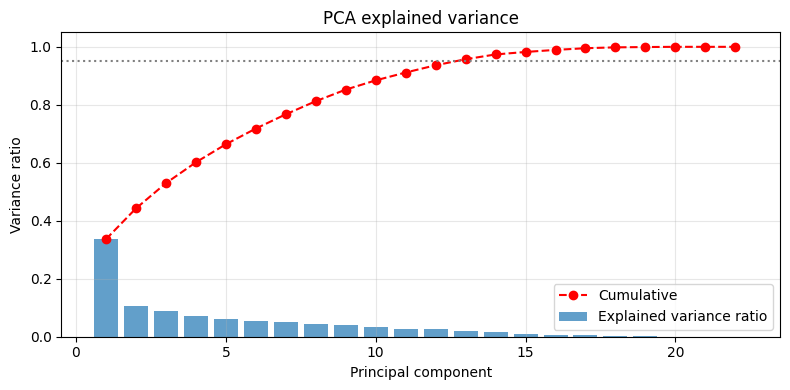

Компонент для 90%: 11
Компонент для 95%: 13
Компонент для 99%: 17


In [15]:
pca_full = PCA(random_state=42).fit(X_train_scaled)

evr = pca_full.explained_variance_ratio_
cum = np.cumsum(evr)

plt.figure(figsize=(8, 4))
plt.bar(range(1, len(evr) + 1), evr, alpha=0.7, label='Explained variance ratio')
plt.plot(range(1, len(evr) + 1), cum, 'r--o', label='Cumulative')
plt.axhline(0.95, color='gray', linestyle=':')
plt.xlabel('Principal component'); plt.ylabel('Variance ratio')
plt.title('PCA explained variance'); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print("Компонент для 90%:", np.argmax(cum >= 0.90) + 1)
print("Компонент для 95%:", np.argmax(cum >= 0.95) + 1)
print("Компонент для 99%:", np.argmax(cum >= 0.99) + 1)

In [16]:
pipe_base = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", KNeighborsClassifier(n_neighbors=5, n_jobs=-1))
])

pipe_pca = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.95, svd_solver="full", random_state=42)),
    ("clf", KNeighborsClassifier(n_neighbors=5, n_jobs=-1))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_base = cross_val_score(pipe_base, X_train, y_train, cv=cv, scoring="f1", n_jobs=1)
cv_pca  = cross_val_score(pipe_pca,  X_train, y_train, cv=cv, scoring="f1", n_jobs=1)

print(f"CV F1  без PCA : {cv_base.mean():.4f} ± {cv_base.std():.4f}")
print(f"CV F1  з PCA   : {cv_pca.mean():.4f} ± {cv_pca.std():.4f}")

CV F1  без PCA : 0.9002 ± 0.0059
CV F1  з PCA   : 0.8932 ± 0.0061


In [21]:
def fit_eval(pipe, label):
    t0 = time.perf_counter()
    pipe.fit(X_train, y_train)
    t1 = time.perf_counter()
    y_pred = pipe.predict(X_test)
    t2 = time.perf_counter()

    n_feat = pipe.named_steps["pca"].n_components_ if "pca" in pipe.named_steps else X_train.shape[1]
    res = {
        "Модель": label,
        "К-сть ознак": n_feat,
        "Accuracy": accuracy_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "Fit, c": t1 - t0,
        "Predict, c": t2 - t1,
    }
    print(f"\n=== {label} ===")
    print(confusion_matrix(y_test, y_pred))
    print(classification_report(y_test, y_pred, digits=4))
    return res

results = [fit_eval(pipe_base, "kNN без PCA"),
           fit_eval(pipe_pca,  "PCA(0.95) + kNN")]

summary = pd.DataFrame(results).set_index("Модель")
print(summary.round(4), "\n")

print(f"Збережена дисперсія: {pipe_pca.named_steps['pca'].explained_variance_ratio_.sum().round(4)}")
print(f"Зменшення к-сті ознак з {X_train.shape[1]} до {pipe_pca.named_steps['pca'].n_components_}")


=== kNN без PCA ===
[[8098  204]
 [ 325 2257]]
              precision    recall  f1-score   support

           0     0.9614    0.9754    0.9684      8302
           1     0.9171    0.8741    0.8951      2582

    accuracy                         0.9514     10884
   macro avg     0.9393    0.9248    0.9317     10884
weighted avg     0.9509    0.9514    0.9510     10884


=== PCA(0.95) + kNN ===
[[8070  232]
 [ 326 2256]]
              precision    recall  f1-score   support

           0     0.9612    0.9721    0.9666      8302
           1     0.9068    0.8737    0.8899      2582

    accuracy                         0.9487     10884
   macro avg     0.9340    0.9229    0.9283     10884
weighted avg     0.9483    0.9487    0.9484     10884

                 К-сть ознак  Accuracy      F1  Fit, c  Predict, c
Модель                                                            
kNN без PCA               22    0.9514  0.8951  0.0321      8.4439
PCA(0.95) + kNN           13    0.9487  0.889

Побудуємо графік залежності якості класифікації від числа PCA-компонент

   n_components      F1  Accuracy   Fit,c  Predict,c
0             2  0.5041    0.7923  0.1415     0.1420
1             3  0.7953    0.9052  0.1588     0.1711
2             5  0.8469    0.9289  0.1727     0.3610
3             8  0.8758    0.9424  0.2058     0.7081
4            10  0.8874    0.9474  0.1406     0.6527
5            12  0.8887    0.9482  0.1706     0.8382
6            15  0.8903    0.9489  0.1894     1.1325
7            22  0.8947    0.9512  0.0399     4.7049 



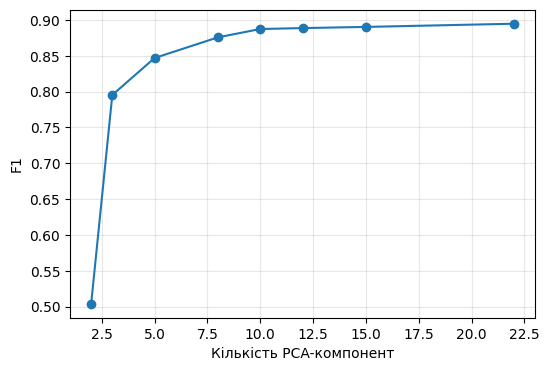

In [25]:
rows = []
for k in [2, 3, 5, 8, 10, 12, 15, X_train.shape[1]]:
    if k > X_train.shape[1]:
        continue
    p = Pipeline([("scaler", StandardScaler()),
                  ("pca", PCA(n_components=k, random_state=42)),
                  ("clf", KNeighborsClassifier(n_neighbors=5, n_jobs=-1))])
    t0 = time.perf_counter(); p.fit(X_train, y_train); t1 = time.perf_counter()
    pred = p.predict(X_test); t2 = time.perf_counter()
    rows.append({"n_components": k, "F1": f1_score(y_test, pred),
                 "Accuracy": accuracy_score(y_test, pred),
                 "Fit,c": t1 - t0, "Predict,c": t2 - t1})

df_k = pd.DataFrame(rows)
print(df_k.round(4), "\n")

plt.figure(figsize=(6, 4))
plt.plot(df_k["n_components"], df_k["F1"], marker='o')
plt.xlabel("Кількість PCA-компонент")
plt.ylabel("F1")
plt.grid(alpha=0.3);

t-SNE: 103.7 c


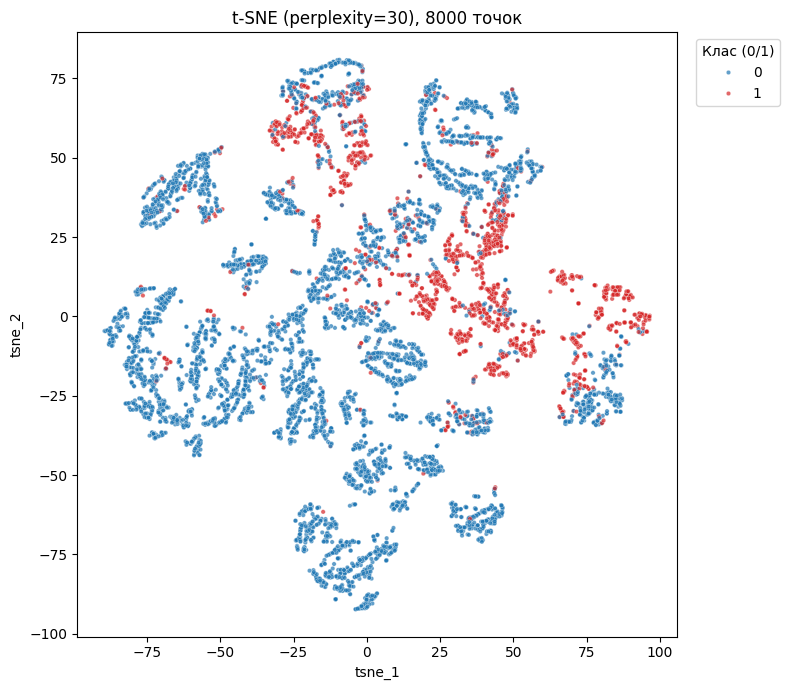

In [18]:
X_sub, _, y_sub, _ = train_test_split(X, y, train_size=8000, random_state=42, stratify=y)

X_sub_std = StandardScaler().fit_transform(X_sub)

t0 = time.perf_counter()
tsne = TSNE(n_components=2, perplexity=30, init="pca",
            learning_rate="auto", random_state=42)
X_tsne = tsne.fit_transform(X_sub_std)
print(f"t-SNE: {time.perf_counter() - t0:.1f} c")

tsne_df = pd.DataFrame({"tsne_1": X_tsne[:, 0], "tsne_2": X_tsne[:, 1], "label": y_sub})

plt.figure(figsize=(8, 7))
sns.scatterplot(data=tsne_df, x="tsne_1", y="tsne_2", hue="label", palette={0: "tab:blue", 1: "tab:red"}, s=10, alpha=0.7)
plt.title(f"t-SNE (perplexity=30), {8000} точок")
plt.legend(title="Клас (0/1)", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

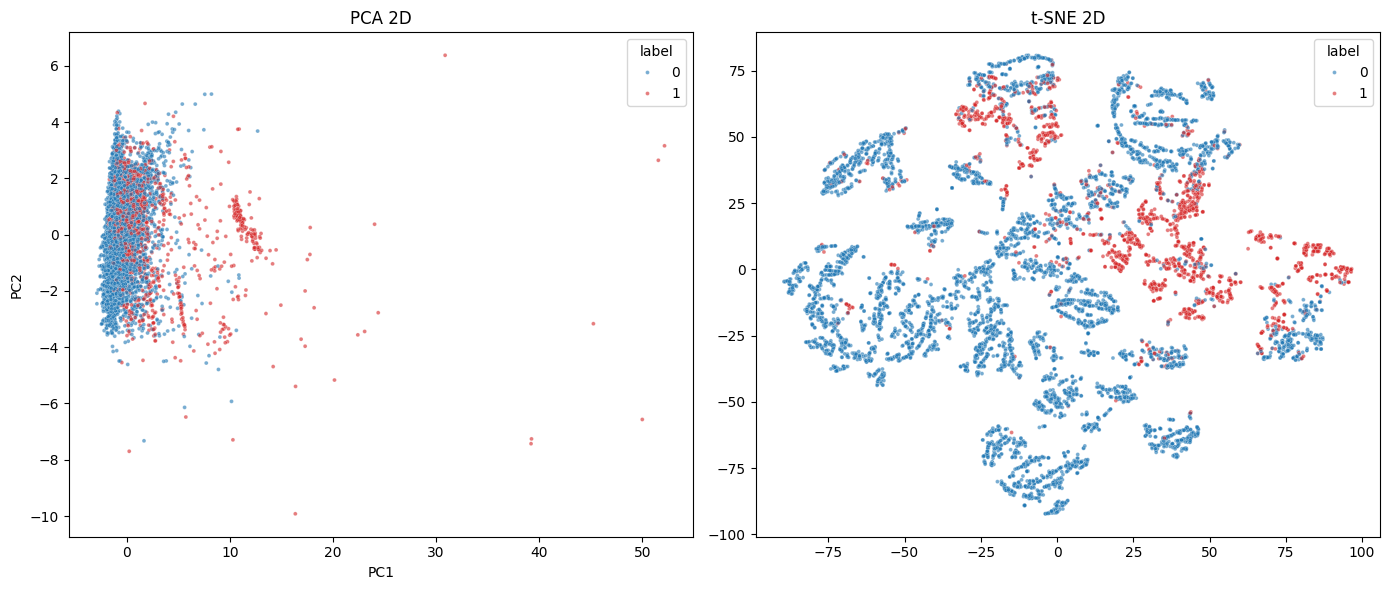

In [19]:
X_pca2 = PCA(n_components=2, random_state=42).fit_transform(X_sub_std)

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
sns.scatterplot(x=X_pca2[:, 0], y=X_pca2[:, 1], hue=y_sub, s=8, alpha=0.6, ax=ax[0], palette={0: "tab:blue", 1: "tab:red"})
ax[0].set_title("PCA 2D")
ax[0].set_xlabel("PC1")
ax[0].set_ylabel("PC2")
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=y_sub, s=8, alpha=0.6, ax=ax[1], palette={0: "tab:blue", 1: "tab:red"})
ax[1].set_title("t-SNE 2D")
plt.tight_layout()
plt.show()

Завдання 2

In [26]:
X_all = df.drop(columns=["label"])
y_true = df["label"].values

X_all_scaled = StandardScaler().fit_transform(X_all)

In [29]:
k_range = range(1, 11)
inertia = []
for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X_all_scaled)
    inertia.append(km.inertia_)

In [31]:
sil_scores = {}
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    lbl = km.fit_predict(X_all_scaled)
    sil_scores[k] = silhouette_score(X_all_scaled, lbl, sample_size=10000, random_state=42)

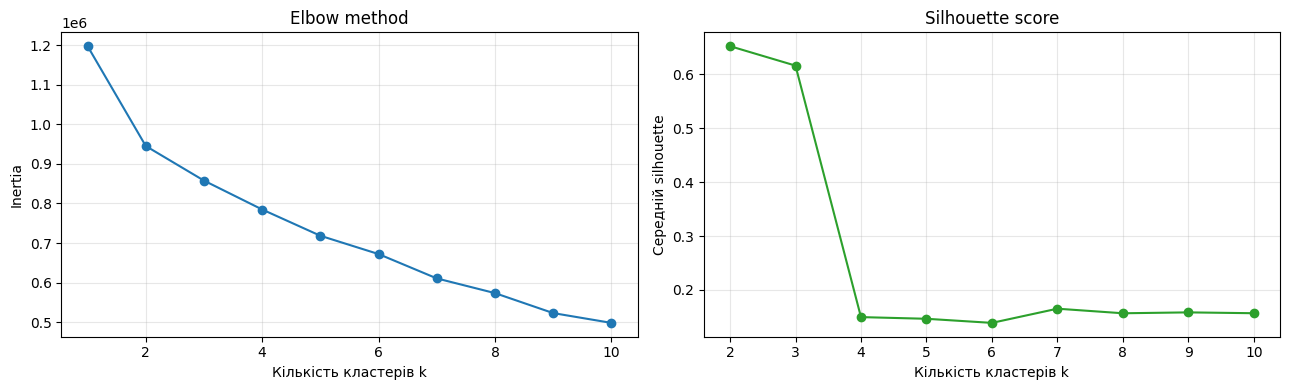

In [32]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

ax[0].plot(list(k_range), inertia, marker="o")
ax[0].set_title("Elbow method")
ax[0].set_xlabel("Кількість кластерів k")
ax[0].set_ylabel("Inertia")
ax[0].grid(alpha=0.3)

ax[1].plot(list(sil_scores.keys()), list(sil_scores.values()), marker="o", color="tab:green")
ax[1].set_title("Silhouette score")
ax[1].set_xlabel("Кількість кластерів k")
ax[1].set_ylabel("Середній silhouette")
ax[1].grid(alpha=0.3)
plt.tight_layout()

In [33]:
best_k = max(sil_scores, key=sil_scores.get)
print(best_k)

2


In [39]:
ks_to_check = sorted({2, best_k})
models = {}
for k in ks_to_check:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X_all_scaled)
    models[k] = km

In [40]:
idx, _ = train_test_split(np.arange(len(X_all_scaled)), train_size=8000, random_state=42, stratify=y_true)

X_vis = X_all_scaled[idx]
y_vis = y_true[idx]

t-SNE: 92.4 c


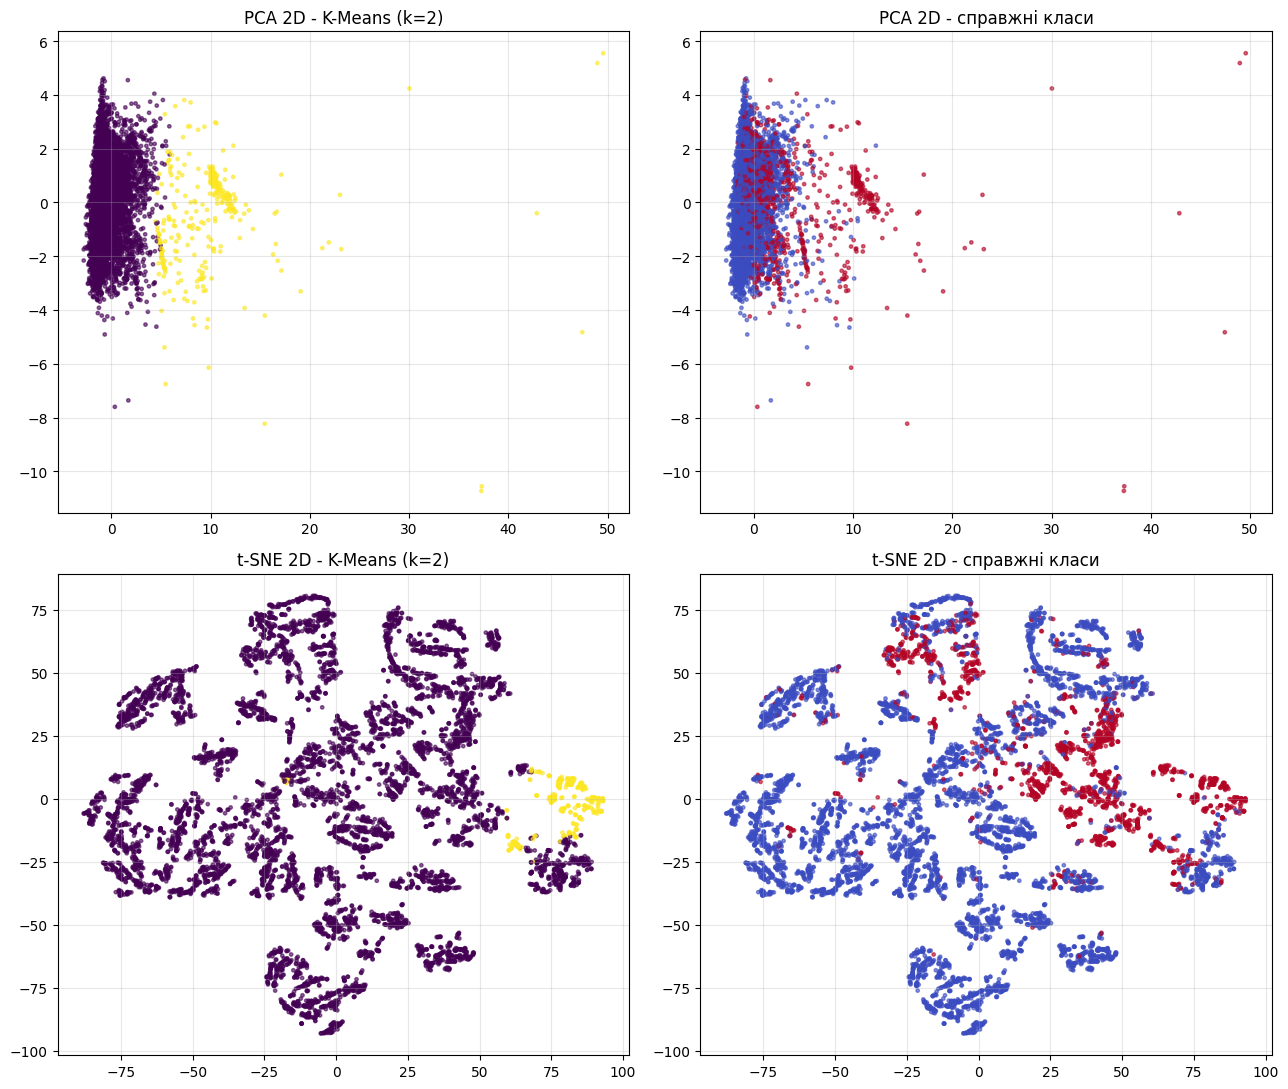

In [42]:
X_pca_vis = PCA(n_components=2, random_state=42).fit(X_all_scaled).transform(X_vis)

t0 = time.perf_counter()
X_tsne_vis = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=42).fit_transform(X_vis)
print(f"t-SNE: {time.perf_counter() - t0:.1f} c")

for k in ks_to_check:
    labels_vis = models[k].labels_[idx]
    fig, axes = plt.subplots(2, 2, figsize=(13, 11))

    axes[0, 0].scatter(X_pca_vis[:, 0], X_pca_vis[:, 1], c=labels_vis, cmap="viridis", s=6, alpha=0.6)
    axes[0, 0].set_title(f"PCA 2D - K-Means (k={k})")
    axes[0, 1].scatter(X_pca_vis[:, 0], X_pca_vis[:, 1], c=y_vis, cmap="coolwarm", s=6, alpha=0.6)
    axes[0, 1].set_title("PCA 2D - справжні класи")

    axes[1, 0].scatter(X_tsne_vis[:, 0], X_tsne_vis[:, 1], c=labels_vis, cmap="viridis", s=6, alpha=0.6)
    axes[1, 0].set_title(f"t-SNE 2D - K-Means (k={k})")
    axes[1, 1].scatter(X_tsne_vis[:, 0], X_tsne_vis[:, 1], c=y_vis, cmap="coolwarm", s=6, alpha=0.6)
    axes[1, 1].set_title("t-SNE 2D - справжні класи")

    for a in axes.ravel():
        a.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


=== k = 2 ===
Таблиця спряженості (кластер x клас):
Клас         0      1
Кластер              
0        41233  10969
1          274   1941

Розподіл класів усередині кластерів, %:
Клас        0     1
Кластер            
0        79.0  21.0
1        12.4  87.6

Підсумкові метрики відповідності кластерів класам:
   Silhouette     ARI     NMI  Homogeneity  Completeness  V-measure  Purity
k                                                                          
2      0.6524  0.1451  0.1099        0.072        0.2318     0.1099  0.7934
Топ-10 ознак, що найбільше відрізняють кластери:
cluster          0      1
eq_cnt      -0.164  3.861
amp_cnt     -0.154  3.633
url_len     -0.138  3.248
letter_cnt  -0.130  3.053
qm_cnt      -0.127  2.997
entropy     -0.126  2.977
digit_cnt   -0.115  2.705
special_cnt -0.114  2.692
path_len    -0.109  2.567
query_len   -0.099  2.332


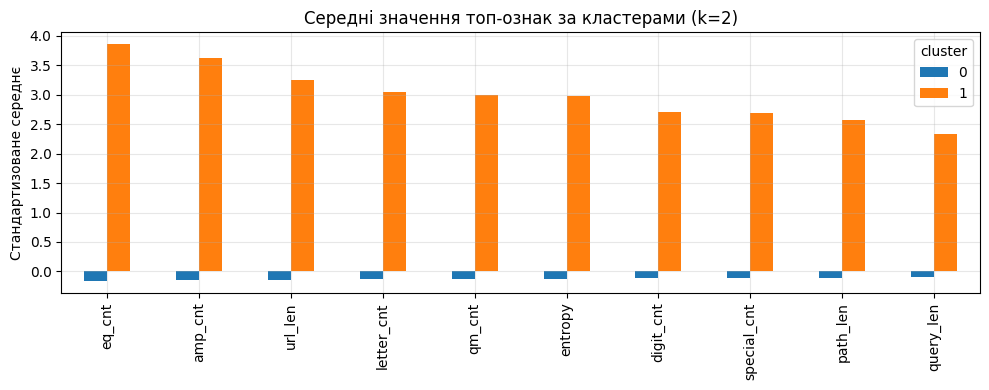

In [43]:
comparison = []
for k in ks_to_check:
    lbl = models[k].labels_
    ct = pd.crosstab(pd.Series(lbl, name="Кластер"), pd.Series(y_true, name="Клас"))
    purity = ct.max(axis=1).sum() / ct.values.sum()

    print(f"\n=== k = {k} ===")
    print("Таблиця спряженості (кластер x клас):")
    print(ct)
    print("\nРозподіл класів усередині кластерів, %:")
    print((ct.div(ct.sum(axis=1), axis=0) * 100).round(1))

    comparison.append({
        "k": k,
        "Silhouette": sil_scores[k],
        "ARI": adjusted_rand_score(y_true, lbl),
        "NMI": normalized_mutual_info_score(y_true, lbl),
        "Homogeneity": homogeneity_score(y_true, lbl),
        "Completeness": completeness_score(y_true, lbl),
        "V-measure": v_measure_score(y_true, lbl),
        "Purity": purity,
    })

print("\nПідсумкові метрики відповідності кластерів класам:")
print(pd.DataFrame(comparison).set_index("k").round(4))

km2 = models[2]
profile = pd.DataFrame(X_all_scaled, columns=X_all.columns)
profile["cluster"] = km2.labels_
cluster_means = profile.groupby("cluster").mean()

diff = (cluster_means.loc[0] - cluster_means.loc[1]).abs().sort_values(ascending=False)
top_feats = diff.head(10).index
print("Топ-10 ознак, що найбільше відрізняють кластери:")
print(cluster_means[top_feats].T.round(3))

cluster_means[top_feats].T.plot(kind="bar", figsize=(10, 4))
plt.title("Середні значення топ-ознак за кластерами (k=2)")
plt.ylabel("Стандартизоване середнє")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Завдання 3

In [51]:
nltk.download("stopwords")
df = pd.read_csv("Phishing_texts.csv")
df = df[["subject", "body", "label"]]

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [52]:
print(f"Пропуски:\n{df.isnull().sum()}")
df["subject"] = df["subject"].fillna("")
df["body"] = df["body"].fillna("")
df = df[(df["subject"].str.strip() != "") | (df["body"].str.strip() != "")]
df = df.dropna(subset=["label"])

Пропуски:
subject    28
body        0
label       0
dtype: int64


In [55]:
print("Дублікатів:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Розмір після очищення:", df.shape)
print(df["label"].value_counts())

Дублікатів: 0
Розмір після очищення: (39154, 3)
label
1    21842
0    17312
Name: count, dtype: int64


In [56]:
df.head()

,subject,body,label
0,Never agree to be a loser,"Buck up, your troubles caused by small dimensi...",1
1,Befriend Jenna Jameson,\nUpgrade your sex and pleasures with these te...,1
2,CNN.com Daily Top 10,>+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+...,1
3,Re: svn commit: r619753 - in /spamassassin/tru...,Would anyone object to removing .so from this ...,0
4,SpecialPricesPharmMoreinfo,\nWelcomeFastShippingCustomerSupport\nhttp://7...,1


In [60]:
stop_words = set(stopwords.words("english"))
punct_table = re.compile(r"[%s]" % re.escape(string.punctuation))

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"https?\S+|www\.\S+", " ", text)
    text = re.sub(r"\S+@\S+", " ", text)
    text = re.sub(r"\d", " ", text)
    text = punct_table.sub(" ", text)
    text = re.sub(r"\s+", " ", text).strip()
    words = [w for w in text.split(" ") if w not in stop_words and len(w) > 2]
    return " ".join(words)

df["subject_clean"] = df["subject"].apply(clean_text)
df["body_clean"] = df["body"].apply(clean_text)
df["text_clean"] = (df["subject_clean"] + " " + df["body_clean"]).str.strip()

df = df[df["text_clean"] != ""].reset_index(drop=True)
print("Розмір після передобробки:", df.shape)

print("\nПриклад до:\n", df["body"].iloc[0][:300])
print("\nПриклад після:\n", df["text_clean"].iloc[0][:300])

Передобробка: 14.9 c
Розмір після передобробки: (39152, 6)

Приклад до:
 Buck up, your troubles caused by small dimension will soon be over!
Become a lover no woman will be able to resist!
http://whitedone.com/


come. Even as Nazi tanks were rolling down the streets, the dreamersphilosopher or a journalist. He was still not sure.I do the same.

Приклад після:
 never agree loser buck troubles caused small dimension soon become lover woman able resist come even nazi tanks rolling streets dreamersphilosopher journalist still sure


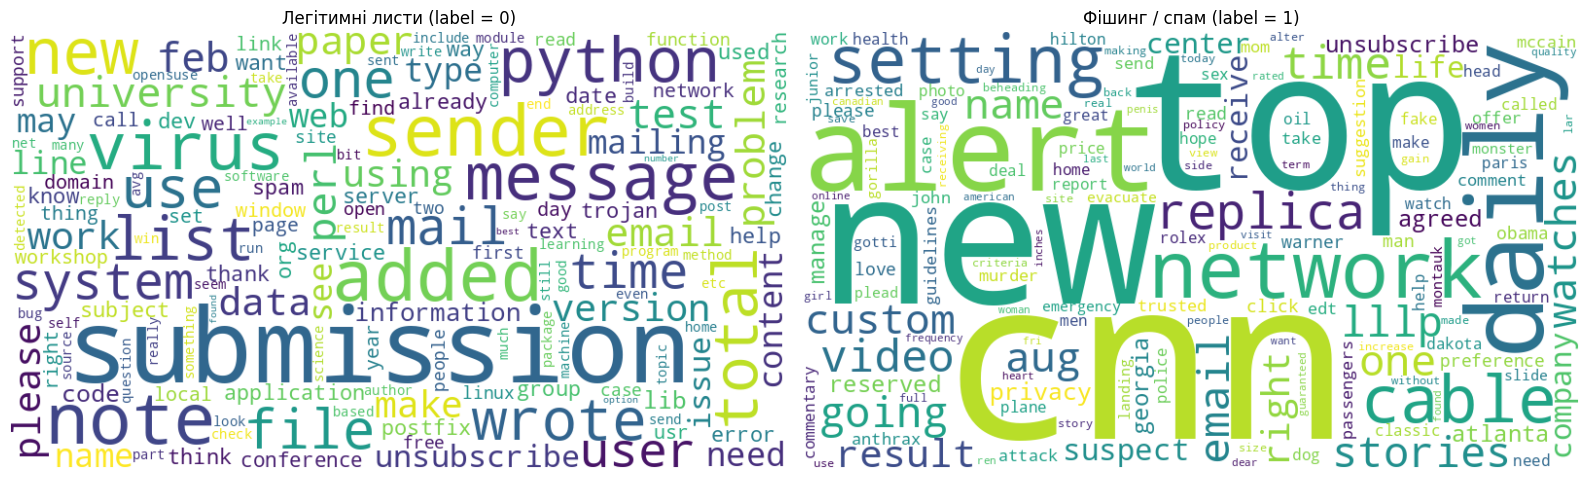

In [61]:
class_names = {0: "Легітимні листи (label = 0)", 1: "Фішинг / спам (label = 1)"}

def plot_wordcloud(label, max_docs=20000):
    texts = df[df["label"] == label]["text_clean"]
    if len(texts) > max_docs:
        texts = texts.sample(max_docs, random_state=42)
    wc = WordCloud(width=800, height=450, background_color="white",
                   max_words=150, collocations=False).generate(" ".join(texts))
    return wc

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, lbl in zip(axes, [0, 1]):
    ax.imshow(plot_wordcloud(lbl), interpolation="bilinear")
    ax.set_title(class_names[lbl])
    ax.axis("off")
plt.tight_layout()

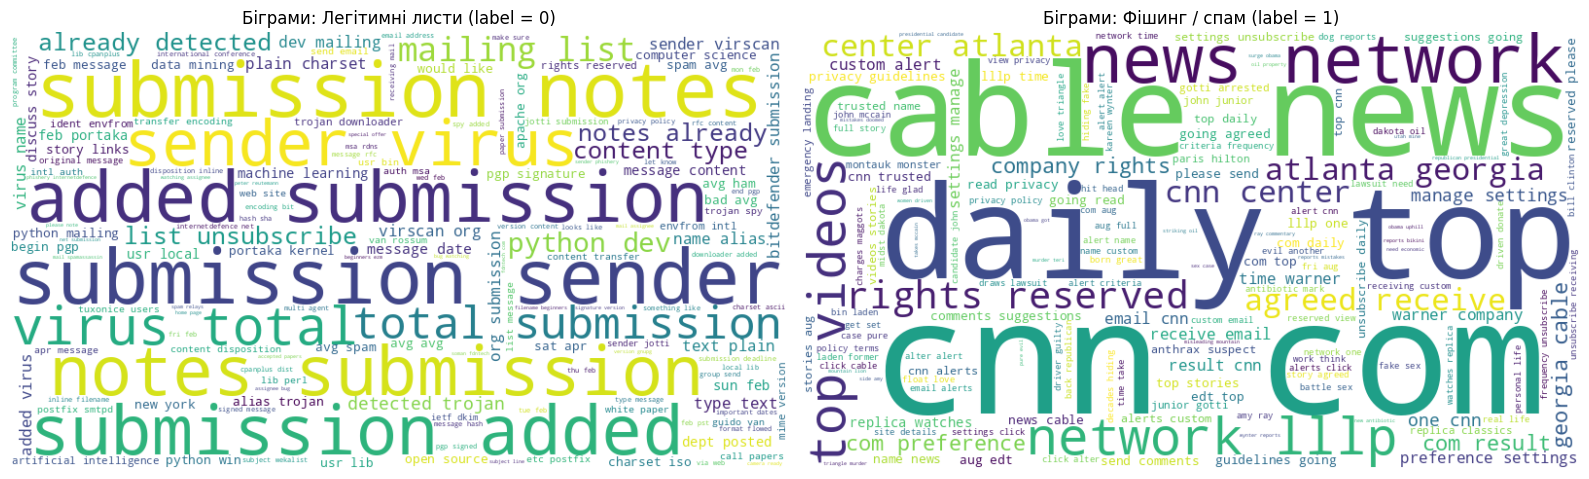

In [64]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, lbl in zip(axes, [0, 1]):
    texts = df[df["label"] == lbl]["text_clean"].sample(min(20000, (df["label"] == lbl).sum()), random_state=42)
    cv = CountVectorizer(ngram_range=(2, 2), max_features=150)
    counts = cv.fit_transform(texts).sum(axis=0).A1
    freqs = dict(zip(cv.get_feature_names_out(), counts))
    wc = WordCloud(width=800, height=450, background_color="white").generate_from_frequencies(freqs)
    ax.imshow(wc, interpolation="bilinear")
    ax.set_title("Біграми: " + class_names[lbl])
    ax.axis("off")
plt.tight_layout()
plt.show()

In [66]:
cv1 = CountVectorizer(max_features=20000)
Xc = cv1.fit_transform(df["text_clean"])
vocab = np.array(cv1.get_feature_names_out())
freq0 = Xc[(df["label"] == 0).values].sum(axis=0).A1 + 1
freq1 = Xc[(df["label"] == 1).values].sum(axis=0).A1 + 1
ratio = np.log((freq1 / freq1.sum()) / (freq0 / freq0.sum()))
mask = (freq0 + freq1) > 200

top1 = vocab[mask][np.argsort(ratio[mask])[::-1][:15]]
top0 = vocab[mask][np.argsort(ratio[mask])[:15]]
print("Слова, характерні для класу 1:", ", ".join(top1))
print("Слова, характерні для класу 0:", ", ".join(top0))

Слова, характерні для класу 1: lllp, montauk, lar, teri, kareen, clampett, wynter, garr, testifies, evacuate, sanctuaries, partying, caylee, evacuates, karadzic
Слова, характерні для класу 0: submission, notes, perl, workshop, linux, opensuse, detected, postfix, papers, spamassassin, trojan, kernel, smtpd, usr, dkim


In [68]:
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["text_clean"], df["label"], test_size=0.2, random_state=42, stratify=df["label"]
)

tfidf = TfidfVectorizer(max_df=0.9, min_df=5, ngram_range=(1, 2), max_features=100000, sublinear_tf=True)
X_train = tfidf.fit_transform(X_train_text)
X_test = tfidf.transform(X_test_text)
print("Розмір TF-IDF матриці (train):", X_train.shape)

Розмір TF-IDF матриці (train): (31321, 100000)


                     Accuracy  F1 (class 1)  F1 macro  Fit, c
Модель                                                       
Logistic Regression    0.9967        0.9970    0.9966  0.6318
Linear SVM             0.9981        0.9983    0.9981  0.9538
Multinomial NB         0.9916        0.9924    0.9915  0.0573

Найкраща модель: Linear SVM

                   precision    recall  f1-score   support

        legit (0)     0.9988    0.9968    0.9978      3463
phishing/spam (1)     0.9975    0.9991    0.9983      4368

         accuracy                         0.9981      7831
        macro avg     0.9982    0.9980    0.9981      7831
     weighted avg     0.9981    0.9981    0.9981      7831



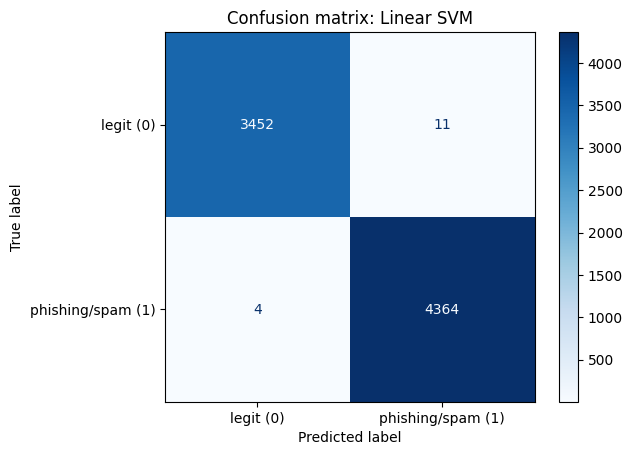

In [71]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Linear SVM": LinearSVC(random_state=42),
    "Multinomial NB": MultinomialNB(alpha=0.1),
}

rows = []
fitted = {}
for name, model in models.items():
    t0 = time.perf_counter()
    model.fit(X_train, y_train)
    fit_t = time.perf_counter() - t0
    pred = model.predict(X_test)
    fitted[name] = (model, pred)
    rows.append({
        "Модель": name,
        "Accuracy": accuracy_score(y_test, pred),
        "F1 (class 1)": f1_score(y_test, pred),
        "F1 macro": f1_score(y_test, pred, average="macro"),
        "Fit, c": fit_t,
    })

summary = pd.DataFrame(rows).set_index("Модель")
print(summary.round(4))

best_name = summary["F1 macro"].idxmax()
best_model, best_pred = fitted[best_name]
print(f"\nНайкраща модель: {best_name}\n")
print(classification_report(y_test, best_pred, digits=4,
                            target_names=["legit (0)", "phishing/spam (1)"]))

cm = confusion_matrix(y_test, best_pred)
ConfusionMatrixDisplay(cm, display_labels=["legit (0)", "phishing/spam (1)"]).plot(cmap="Blues", values_format="d")
plt.title(f"Confusion matrix: {best_name}")
plt.show()

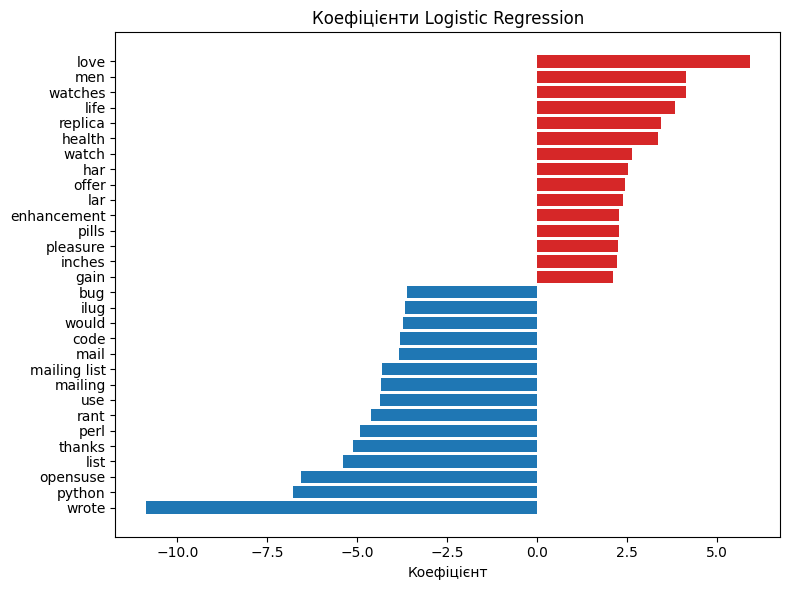

In [74]:
lr = fitted["Logistic Regression"][0]
feat_names = np.array(tfidf.get_feature_names_out())
coefs = lr.coef_[0]
order = np.argsort(coefs)

top_neg = feat_names[order[:15]]
top_pos = feat_names[order[-15:][::-1]]

fig, ax = plt.subplots(figsize=(8, 6))
idx_plot = np.concatenate([order[:15], order[-15:]])
ax.barh(feat_names[idx_plot], coefs[idx_plot],
        color=["tab:blue"] * 15 + ["tab:red"] * 15)
ax.set_title("Коефіцієнти Logistic Regression")
ax.set_xlabel("Коефіцієнт")
plt.tight_layout()
plt.show()